# Number theory 3: Modular arithmetic

*Learning path: number theory, part 3 of 4.* [Index](README.md) · Previous: [Prime factoring](02-prime-factoring.ipynb) · Next: [Cryptography](04-cryptography.ipynb)

Clock arithmetic: 5 hours after 9 o'clock it is 2 o'clock, because $9 + 5 = 14$ and we only keep the remainder after
dividing by 12. Gauss turned this into a whole arithmetic in 1801, and it is the arithmetic of computers, check digits,
calendars and cryptography. You will learn

* congruences $a \equiv b \pmod n$, and addition and multiplication tables mod $n$,
* the divisibility tests for 3, 9 and 11, and why they work,
* fast powers with **repeated squaring** (`powmod`),
* **Fermat's little theorem** and Euler's theorem,
* dividing mod $n$: **inverses**, and when they exist,
* the **Chinese remainder theorem**,
* the **order** of a number and primitive roots, and why $1/7 = 0.142857142857\ldots$ repeats after 6 digits.

## 1. Congruences

Two numbers are **congruent modulo $n$**, written $a \equiv b \pmod n$, when they have the same remainder after
dividing by $n$, or equivalently when $n$ divides $a - b$. `mod(a, n)` gives the remainder, always between $0$ and
$n - 1$, also for negative $a$:

In [1]:
mod(9 + 5, 12)
mod(38, 12)
mod(-3, 7)

2
2
4

$-3 \equiv 4 \pmod 7$: three days before a Thursday is a Monday, four days after it too.

The key fact: you can take remainders *before* adding or multiplying, and the result is the same. So mod $n$ there
are only $n$ numbers, $0, 1, \ldots, n - 1$, and they have their own addition and multiplication tables. The
multiplication table mod 7 below has one row per $k = 0, \ldots, 6$; the row is
`mod(k*[0 1 2 3 4 5 6], 7)`, the products $k\cdot 0, \ldots, k\cdot 6$ reduced mod 7 (`mod` works on a whole list at once):

In [2]:
table(mod(k*[0 1 2 3 4 5 6], 7), k, 0, 6)

0	0	0	0	0	0	0
0	1	2	3	4	5	6
0	2	4	6	1	3	5
0	3	6	2	5	1	4
0	4	1	5	2	6	3
0	5	3	1	6	4	2
0	6	5	4	3	2	1

Every row except the first contains each of $0, \ldots, 6$ exactly once. That means you can always divide by a
nonzero number mod 7 (section 4). Mod 10 it is different: the row of 2 only has even numbers, and $2 \cdot 5 = 10 \equiv 0$
although neither factor is 0:

In [3]:
table(mod(k*[0 1 2 3 4 5 6 7 8 9], 10), k, 0, 9)

0	0	0	0	0	0	0	0	0	0
0	1	2	3	4	5	6	7	8	9
0	2	4	6	8	0	2	4	6	8
0	3	6	9	2	5	8	1	4	7
0	4	8	2	6	0	4	8	2	6
0	5	0	5	0	5	0	5	0	5
0	6	2	8	4	0	6	2	8	4
0	7	4	1	8	5	2	9	6	3
0	8	6	4	2	0	8	6	4	2
0	9	8	7	6	5	4	3	2	1

## 2. Divisibility tests

$10 \equiv 1 \pmod 9$, so $10^k \equiv 1$ as well, and a number $d_k\ldots d_1 d_0 = \sum d_i 10^i$ is congruent to
the sum of its digits mod 9. That is the old rule "a number is divisible by 9 (or 3) when its digit sum is":

In [4]:
mod(123456789, 9)
mod(1 + 2 + 3 + 4 + 5 + 6 + 7 + 8 + 9, 9)

0
0

Since $10 \equiv -1 \pmod{11}$, the powers of 10 alternate between $1$ and $-1$ mod 11, and the test for 11 is the
alternating digit sum. Each row of the table is $[k, 10^k \bmod 9, 10^k \bmod 11]$:

In [5]:
table([k, mod(10^k, 9), mod(10^k, 11)], k, 0, 5)
mod(918082, 11)
mod(2 - 8 + 0 - 8 + 1 - 9, 11)

0	1	1
1	1	10
2	1	1
3	1	10
4	1	1
5	1	10
0
0

## 3. Fast powers

What is $3^{100} \bmod 7$? Computing $3^{100}$ first gives a 48-digit number, already more than the 38 digits Galileo
keeps exact, and for the exponents of lesson 4 (hundreds of digits) it is impossible for any computer. **Repeated squaring** keeps every number small. Square again and again, reducing mod 7
each time: $3^1, 3^2, 3^4, 3^8, \ldots$ The table has the columns $k$, the exponent $2^k$, and $3^{2^k} \bmod 7$:

In [6]:
table([k, 2^k, powmod(3, 2^k, 7)], k, 0, 6)

0	1	3
1	2	2
2	4	4
3	8	2
4	16	4
5	32	2
6	64	4

Now write the exponent in binary, $100 = 64 + 32 + 4$, so $3^{100} = 3^{64}\cdot 3^{32}\cdot 3^4 \equiv 4\cdot 2\cdot 4 = 32 \equiv 4$.
That took 6 squarings and 2 multiplications instead of 99 multiplications. `powmod(a, e, n)` does exactly this:

In [7]:
mod(4*2*4, 7)
powmod(3, 100, 7)

4
4

For an exponent with $d$ digits repeated squaring needs only about $3.3\,d$ squarings, so `powmod` is fast even for
exponents with hundreds of digits.

## 4. Fermat's little theorem

Look at the powers $a^{p-1}$ mod a prime $p$. Each row is $[a, a^6 \bmod 7, a^{10} \bmod 11]$:

In [8]:
table([a, powmod(a, 6, 7), powmod(a, 10, 11)], a, 1, 6)

1	1	1
2	1	1
3	1	1
4	1	1
5	1	1
6	1	1

Always 1. **Fermat's little theorem** (1640): if $p$ is prime and $p$ does not divide $a$, then

$$a^{p-1} \equiv 1 \pmod p.$$

Why: multiplying the numbers $1, 2, \ldots, p - 1$ by $a$ just shuffles them (that is what the rows of the
multiplication table showed). So $(a\cdot1)(a\cdot2)\cdots(a(p-1)) \equiv 1\cdot2\cdots(p-1)$, and cancelling the common
factor $(p-1)!$ leaves $a^{p-1} \equiv 1$. This is the test of lesson 2 that 91 failed.

### Euler's theorem

For a modulus $n$ that is not prime, only the numbers sharing no factor with $n$ behave this way. Euler counted them:
the **totient** $\varphi(n)$ is the number of $a$ between 1 and $n$ with $\gcd(a, n) = 1$. For $n = 10$ those are
$1, 3, 7, 9$, so $\varphi(10) = 4$. **Euler's theorem** (1763): $a^{\varphi(n)} \equiv 1 \pmod n$ when $\gcd(a, n) = 1$.

In [9]:
totient(10)
totient(7)
totient(1000003*1000033)
(1000003 - 1)*(1000033 - 1)
powmod(3, totient(10), 10)

4
6
1000034000064
1000034000064
1

For a product of two primes, $\varphi(pq) = (p - 1)(q - 1)$. Computing $\varphi(n)$ is easy if you know $p$ and $q$ and,
as far as anyone knows, as hard as factoring if you don't. That is the heart of RSA (lesson 4).

A consequence: exponents can be reduced mod $\varphi(n)$. The last digit of $7^{2026}$ is $7^{2026} \bmod 10$, and
$2026 = 506\cdot4 + 2$, so it is the last digit of $7^2 = 49$:

In [10]:
mod(2026, 4)
powmod(7, 2026, 10)

2
9

## 5. Dividing: inverses

Solving $3x \equiv 4 \pmod 7$ means dividing by 3. Mod 7, "$1/3$" is the number $u$ with $3u \equiv 1$, the
**inverse** of 3. From the multiplication table: $3\cdot5 = 15 \equiv 1$, so $u = 5$. `modinv(a, n)` finds it with
Euclid's algorithm (from Bézout's identity $ua + vn = 1$), and then $x \equiv 5\cdot 4$:

In [11]:
modinv(3, 7)
x = mod(modinv(3, 7)*4, 7)
mod(3*x, 7)

5
6
4

An inverse of $a$ mod $n$ exists exactly when $\gcd(a, n) = 1$. Mod 10 the numbers 2, 4, 5, 6, 8 have no inverse,
which is why their rows in the table above miss the 1. Mod a prime every nonzero number has one, so mod a prime
you can add, subtract, multiply and divide: a **finite field**.

In [12]:
gcd(4, 10)
table([a, modinv(a, 11)], a, 1, 10)

2
1	1
2	6
3	4
4	3
5	9
6	2
7	8
8	7
9	5
10	10

## 6. The Chinese remainder theorem

The *Sunzi Suanjing* (China, 3rd to 5th century) asks: a number leaves remainder 2 when divided by 3, remainder 3
when divided by 5 and remainder 2 when divided by 7. What is it? `crt([remainders], [moduli])` answers with the
smallest such number:

In [13]:
crt([2 3 2], [3 5 7])
mod(23, [3 5 7])

23
2	3	2

The theorem says the answer always exists and is unique mod $3\cdot5\cdot7 = 105$, as long as the moduli have no common
factors: knowing $x$ mod 3, mod 5 and mod 7 is the same as knowing $x$ mod 105. So 128, 233, ... also work. Computers
use this to split one big calculation mod $n = pq$ into two small ones mod $p$ and mod $q$; RSA decryption is about 4
times faster that way.

## 7. Orders, cycles and repeating decimals

The powers of a number mod $n$ repeat in a cycle. The first $k > 0$ with $a^k \equiv 1$ is the **order** of $a$, and
`multorder(a, n)` computes it. By Fermat the order divides $p - 1$:

In [14]:
iterate(mod(10*x, 7), x, 1, 12)
multorder(10, 7)

1	3	2	6	4	5	1	3	2	6	4	5	1
6

This explains decimal fractions. Long division of $1/7$ computes the remainders $10^k \bmod 7$, which are
$1, 3, 2, 6, 4, 5$ and then repeat, so the digits of $1/7 = 0.142857\,142857\ldots$ repeat with period 6, the order of 10
mod 7. The table lists primes $p$ and the period of $1/p$:

In [15]:
table([prime(k), multorder(10, prime(k))], k, 4, 12)
eval(1/13)

7	6
11	2
13	6
17	16
19	18
23	22
29	28
31	15
37	3
0.07692307692307693

$1/13 = 0.076923\,076923\ldots$ has period 6, and $1/17$ has the longest possible period $16 = 17 - 1$.

A number whose order is the full $p - 1$ is a **primitive root**: its powers run through all of $1, \ldots, p - 1$.
`primroot(p)` finds the smallest one. The plot shows the powers of the primitive root 2 mod 101: across is the exponent
$k$, up is $2^k \bmod 101$. Each of the numbers $1, \ldots, 100$ appears exactly once, in what looks like random order:

2

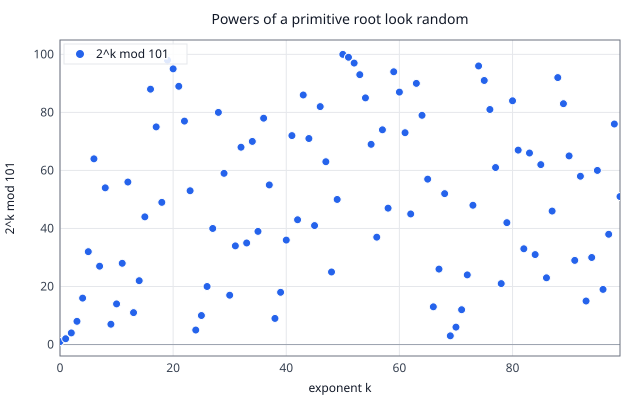

In [16]:
primroot(101)
D = table([k, powmod(2, k, 101)], k, 0, 99);
labels(title(legend(scatter(D, [k y]), "2^k mod 101"), "Powers of a primitive root look random"), "exponent k", "2^k mod 101")

Going forward ($k \mapsto 2^k \bmod 101$) is easy with `powmod`. Going back (given $y$, find $k$ with
$2^k \equiv y$) is the **discrete logarithm** problem, and for primes with hundreds of digits nobody knows a fast way.
Lesson 4 builds a key exchange on it.

## Summary

* $a \equiv b \pmod n$ when $n \mid a - b$. `mod` reduces, also whole lists.
* Divisibility by 9 and 11 from $10 \equiv 1$ and $10 \equiv -1$.
* `powmod(a, e, n)`: fast powers by repeated squaring.
* Fermat: $a^{p-1} \equiv 1 \pmod p$; Euler: $a^{\varphi(n)} \equiv 1 \pmod n$; `totient`.
* `modinv(a, n)` exists when $\gcd(a, n) = 1$; mod a prime you can divide by anything nonzero.
* `crt` combines remainders; `multorder` is the length of the cycle of powers; `primroot` gives a number whose powers
  hit everything.

**Try it:** which day of the week will 1 January 2100 be? (Hint: count days mod 7; 1 January 2026 was a Thursday, and
there are 18 leap days in between.) Check the ISBN-10 rule: $\sum_{i=1}^{10} i\cdot d_i \equiv 0 \pmod{11}$ for the
digits of 0-306-40615-2. Find the period of $1/97$.

Next: [Cryptography](04-cryptography.ipynb), where `powmod`, `modinv` and $\varphi$ become RSA.

## Sources

1. C. F. Gauss, *Disquisitiones Arithmeticae*, Leipzig (1801). Sections 1–3 (congruences, Fermat's theorem, primitive roots, decimal periods).
2. L. Euler, "Theoremata arithmetica nova methodo demonstrata", *Novi Commentarii Academiae Scientiarum Petropolitanae* 8 (1763) 74–104.
3. K. H. Rosen, *Elementary Number Theory and Its Applications*, 6th ed., Pearson (2011). Chapters 4, 6 and 9.
4. *Sunzi Suanjing* (Master Sun's Mathematical Manual), 3rd–5th century, Problem 26.